In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
GRID_SIZE = 4
N_STATES = 16
N_ACTIONS = 4

START_STATE = 0
GOAL_STATE = 15

ACTIONS = ["Up", "Down", "Left", "Right"]
ARROWS = ["↑", "↓", "←", "→"]

def take_action(state, action):

    row, col = divmod(state, GRID_SIZE)

    if action == 0:
        row = max(0, row - 1)
    elif action == 1:
        row = min(3, row + 1)
    elif action == 2:
        col = max(0, col - 1)
    else:
        col = min(3, col + 1)

    next_state = row * GRID_SIZE + col

    reward = 10 if next_state == GOAL_STATE else -1

    return next_state, reward

In [3]:
ALPHA = 0.1
GAMMA = 0.9
EPISODES = 1000
MAX_STEPS = 100

In [4]:
def train_q_learning(epsilon):

    Q = np.zeros((N_STATES, N_ACTIONS))

    rewards = []
    steps_list = []
    success_list = []

    for episode in range(EPISODES):

        state = START_STATE
        total_reward = 0
        success = False

        for step in range(MAX_STEPS):

            # Epsilon-greedy selection
            if np.random.random() < epsilon:
                action = np.random.randint(N_ACTIONS)
            else:
                action = np.argmax(Q[state])

            next_state, reward = take_action(state, action)

            # Q-learning update
            target = reward + GAMMA * np.max(Q[next_state])

            if next_state == GOAL_STATE:
                target = reward

            Q[state, action] += ALPHA * (
                target - Q[state, action]
            )

            total_reward += reward
            state = next_state

            if state == GOAL_STATE:
                success = True
                break

        rewards.append(total_reward)
        steps_list.append(step + 1)
        success_list.append(int(success))

    return Q, np.array(rewards), np.array(steps_list), np.array(success_list)

In [5]:
epsilon_values = [0.5, 0.1, 0.01]

results = {}

for eps in epsilon_values:

    Q, rewards, steps, success = train_q_learning(eps)

    results[eps] = {
        "Q": Q,
        "rewards": rewards,
        "steps": steps,
        "success": success
    }

print("Training completed!")

Training completed!


In [6]:
summary = []

for eps, result in results.items():

    summary.append({
        "Epsilon": eps,
        "Average Reward": result["rewards"][-100:].mean(),
        "Success Rate (%)": result["success"][-100:].mean() * 100,
        "Average Steps": result["steps"][-100:].mean()
    })

summary_df = pd.DataFrame(summary)

print(summary_df.round(2))

   Epsilon  Average Reward  Success Rate (%)  Average Steps
0     0.50           -0.77             100.0          11.77
1     0.10            4.32             100.0           6.68
2     0.01            4.91             100.0           6.09


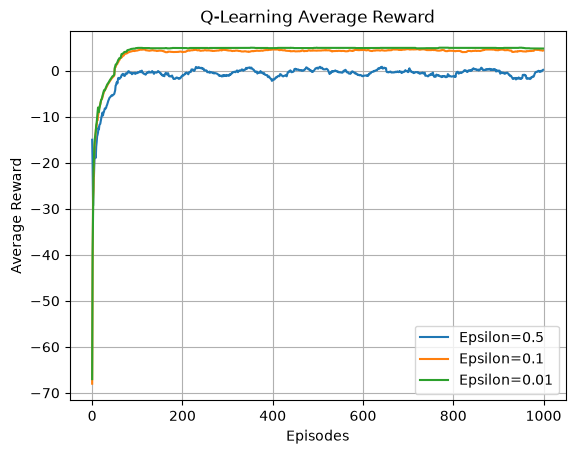

In [7]:
for eps, result in results.items():

    avg = pd.Series(result["rewards"]).rolling(
        50, min_periods=1
    ).mean()

    plt.plot(avg, label=f"Epsilon={eps}")

plt.title("Q-Learning Average Reward")
plt.xlabel("Episodes")
plt.ylabel("Average Reward")
plt.legend()
plt.grid()
plt.show()

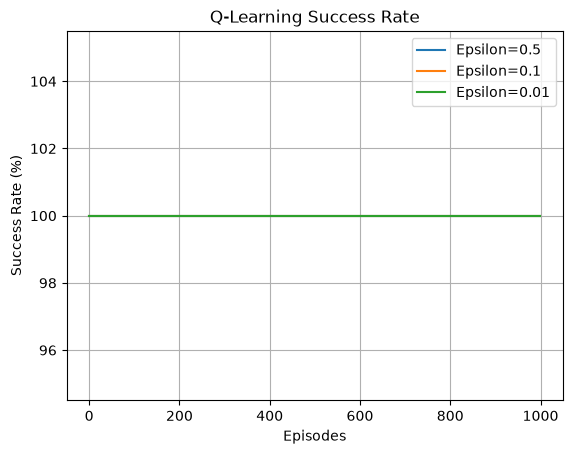

In [8]:
for eps, result in results.items():

    success_rate = pd.Series(result["success"]).rolling(
        50, min_periods=1
    ).mean() * 100

    plt.plot(success_rate, label=f"Epsilon={eps}")

plt.title("Q-Learning Success Rate")
plt.xlabel("Episodes")
plt.ylabel("Success Rate (%)")
plt.legend()
plt.grid()
plt.show()

In [9]:
Q_final = results[0.1]["Q"]

q_table = pd.DataFrame(
    Q_final,
    columns=ACTIONS
)

print("Final Q-Table:")
print(q_table.round(2))

Final Q-Table:
      Up   Down  Left  Right
0   0.52   1.81  0.31   1.30
1  -1.39   3.09 -0.96  -1.33
2  -0.77   0.04 -0.81  -0.78
3  -0.48   1.48 -0.55  -0.42
4   0.43   2.56  1.64   3.12
5   1.07   4.58  1.44   3.15
6  -0.62   1.41 -0.45   6.04
7  -0.29   7.96  1.27   1.01
8  -0.30  -0.81 -0.67   4.56
9   2.92   5.48  2.77   6.20
10  3.70   8.00  4.18   7.45
11  1.03  10.00  2.13   1.51
12 -0.41  -0.39 -0.48   0.23
13  0.18  -0.20 -0.22   7.97
14  5.43   7.52  5.27  10.00
15  0.00   0.00  0.00   0.00


In [10]:
policy = []

for state in range(N_STATES):

    if state == START_STATE:
        policy.append("S")

    elif state == GOAL_STATE:
        policy.append("G")

    else:
        action = np.argmax(Q_final[state])
        policy.append(ARROWS[action])

policy_grid = np.array(policy).reshape(4, 4)

print("Learned Policy:")
print(policy_grid)

Learned Policy:
[['S' '↓' '↓' '↓']
 ['→' '↓' '→' '↓']
 ['→' '→' '↓' '↓']
 ['→' '→' '→' 'G']]


In [11]:
state = START_STATE
path = [state]
total_reward = 0

for step in range(50):

    action = np.argmax(Q_final[state])

    next_state, reward = take_action(state, action)

    total_reward += reward
    state = next_state
    path.append(state)

    if state == GOAL_STATE:
        break

print("Path:", path)
print("Number of Moves:", len(path) - 1)
print("Total Reward:", total_reward)

if state == GOAL_STATE:
    print("Goal Reached!")
else:
    print("Goal Not Reached!")

Path: [0, 4, 5, 9, 10, 14, 15]
Number of Moves: 6
Total Reward: 5
Goal Reached!
